# Automação de extratos de boletos
**Lucas Freire Martins | Python + Pandas + Pillow**

Base sintética: 10 clientes e 100 boletos. Os documentos são fictícios e não servem para validação cadastral. A situação dos boletos é fornecida pela base, com referência em **19/10/2026**, e não é recalculada pela data atual.

**Como executar no Colab:** envie `boletos_ficticios.csv` para `/content/` e execute as células em ordem. O notebook também corrige as 14 emissões futuras da versão inicial dessa base fictícia. Essa correção é específica deste exercício; em dados reais, inconsistências devem ser investigadas.

O mascaramento é parcial: o CSV e as primeiras saídas do notebook mantêm os dados de origem. Use apenas a base fictícia neste portfólio.


## 1. Ler e conferir os dados

In [1]:
import pandas as pd

df = pd.read_csv(
    "/content/boletos_ficticios.csv",
    sep=";", decimal=",", dtype={"cpf_cnpj": str}
)

# Corrigir somente as emissões futuras da base fictícia original.
emissao = pd.to_datetime(df["data_emissao"])
referencia = pd.to_datetime(df["data_referencia"])
correcao = emissao > referencia
df.loc[correcao, "data_emissao"] = df.loc[correcao, "data_referencia"]

print(f"Clientes: {df['cliente_id'].nunique()} | Boletos: {len(df)}")
print(f"Emissões futuras corrigidas nesta execução: {correcao.sum()}")
display(df.head())

Clientes: 10 | Boletos: 100
Emissões futuras corrigidas nesta execução: 0


,cliente_id,nome,tipo_pessoa,cpf_cnpj,email,boleto_id,data_emissao,data_vencimento,data_pagamento,valor,situacao,data_referencia
0,C001,Cliente Fictício 01,PF,00000000001,cliente01@example.com,B0001,2026-06-29,2026-07-29,2026-07-25,115.56,Pago,2026-10-19
1,C001,Cliente Fictício 01,PF,00000000001,cliente01@example.com,B0002,2026-10-07,2026-11-06,NaN,691.96,Em aberto,2026-10-19
2,C001,Cliente Fictício 01,PF,00000000001,cliente01@example.com,B0003,2026-08-21,2026-09-20,NaN,415.79,Vencido,2026-10-19
3,C001,Cliente Fictício 01,PF,00000000001,cliente01@example.com,B0004,2026-09-05,2026-10-05,2026-10-10,1991.61,Pago,2026-10-19
4,C001,Cliente Fictício 01,PF,00000000001,cliente01@example.com,B0005,2026-10-19,2026-11-23,NaN,277.90,Em aberto,2026-10-19


## 2. Selecionar um cliente

In [2]:
cliente = df[df["cliente_id"] == "C001"].copy()

display(cliente)

,cliente_id,nome,tipo_pessoa,cpf_cnpj,email,boleto_id,data_emissao,data_vencimento,data_pagamento,valor,situacao,data_referencia
0,C001,Cliente Fictício 01,PF,00000000001,cliente01@example.com,B0001,2026-06-29,2026-07-29,2026-07-25,115.56,Pago,2026-10-19
1,C001,Cliente Fictício 01,PF,00000000001,cliente01@example.com,B0002,2026-10-07,2026-11-06,NaN,691.96,Em aberto,2026-10-19
2,C001,Cliente Fictício 01,PF,00000000001,cliente01@example.com,B0003,2026-08-21,2026-09-20,NaN,415.79,Vencido,2026-10-19
3,C001,Cliente Fictício 01,PF,00000000001,cliente01@example.com,B0004,2026-09-05,2026-10-05,2026-10-10,1991.61,Pago,2026-10-19
4,C001,Cliente Fictício 01,PF,00000000001,cliente01@example.com,B0005,2026-10-19,2026-11-23,NaN,277.90,Em aberto,2026-10-19


## 3. Mascarar os dados da cópia

In [3]:
cliente["cpf_cnpj"] = "***" + cliente["cpf_cnpj"].str[-2:]

cliente["email"] = (
    cliente["email"].str[0] + "***@" +
    cliente["email"].str.split("@").str[1]
)

display(cliente[["cliente_id", "cpf_cnpj", "email"]])

,cliente_id,cpf_cnpj,email
0,C001,***01,c***@example.com
1,C001,***01,c***@example.com
2,C001,***01,c***@example.com
3,C001,***01,c***@example.com
4,C001,***01,c***@example.com


## 4. Calcular os cartões de resumo

In [4]:
quantidade = len(cliente)
total = cliente["valor"].sum()

print("Quantidade de boletos:", quantidade)
print("Valor total: R$", round(total, 2))

Quantidade de boletos: 5
Valor total: R$ 3492.82


## 5. Formatar a tabela

In [5]:
extrato = cliente[
    ["cpf_cnpj", "email", "data_vencimento", "valor", "situacao"]
].copy()

extrato["data_vencimento"] = pd.to_datetime(
    extrato["data_vencimento"]
).dt.strftime("%d/%m/%Y")

def formatar_real(valor):
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

extrato["valor"] = extrato["valor"].apply(formatar_real)

extrato.columns = ["CPF/CNPJ", "E-mail", "Vencimento", "Valor", "Situação"]

display(extrato)

,CPF/CNPJ,E-mail,Vencimento,Valor,Situação
0,***01,c***@example.com,29/07/2026,"R$ 115,56",Pago
1,***01,c***@example.com,06/11/2026,"R$ 691,96",Em aberto
2,***01,c***@example.com,20/09/2026,"R$ 415,79",Vencido
3,***01,c***@example.com,05/10/2026,"R$ 1.991,61",Pago
4,***01,c***@example.com,23/11/2026,"R$ 277,90",Em aberto


## 6. Preparar as fontes e o desenho
O Matplotlib inclui fontes DejaVu. Usamos seus arquivos locais, sem baixar fontes da internet. A função abaixo reúne o desenho para reutilizá-lo em cada cliente.


In [6]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from matplotlib import font_manager
from IPython.display import display

preto, amarelo, branco = "#191919", "#E8BC00", "#F5F5F2"
regular = font_manager.findfont("DejaVu Sans", fallback_to_default=False)
negrito = font_manager.findfont(
    font_manager.FontProperties(family="DejaVu Sans", weight="bold"),
    fallback_to_default=False
)
fonte = ImageFont.truetype(regular, 20)
titulo = ImageFont.truetype(negrito, 36)
destaque = ImageFont.truetype(negrito, 30)


def gerar_imagem(cliente_id, extrato, total):
    quantidade = len(extrato)
    altura = 400 + quantidade * 50
    imagem = Image.new("RGB", (1200, altura), branco)
    desenho = ImageDraw.Draw(imagem)

    desenho.text((40, 25), "EXTRATO DE BOLETOS", font=titulo, fill=preto)
    desenho.text((40, 78), f"Cliente: {cliente_id}", font=fonte, fill=preto)
    desenho.text((700, 78), "Referência: 19/10/2026", font=fonte, fill=preto)

    desenho.rectangle((40, 130, 580, 240), fill=preto)
    desenho.rectangle((620, 130, 1160, 240), fill=amarelo)
    desenho.text((65, 145), "QUANTIDADE DE BOLETOS", font=fonte, fill=branco)
    desenho.text((65, 185), str(quantidade), font=destaque, fill=branco)
    desenho.text((645, 145), "VALOR TOTAL", font=fonte, fill=preto)
    desenho.text((645, 185), formatar_real(total), font=destaque, fill=preto)

    posicoes = [55, 230, 550, 760, 980]
    desenho.rectangle((40, 270, 1160, 315), fill=preto)
    for x, coluna in zip(posicoes, extrato.columns):
        desenho.text((x, 280), coluna, font=fonte, fill=branco)

    for i, linha in enumerate(extrato.itertuples(index=False, name=None)):
        y = 315 + i * 50
        cor = "#EAEAEA" if i % 2 == 0 else branco
        desenho.rectangle((40, y, 1160, y + 50), fill=cor)
        for x, valor in zip(posicoes, linha):
            desenho.text((x, y + 12), str(valor), font=fonte, fill=preto)

    desenho.text(
        (40, altura - 45),
        "Dados fictícios | Lucas Freire Martins | Python + Pandas",
        font=fonte, fill=preto
    )
    return imagem

## 7. Visualizar o primeiro extrato

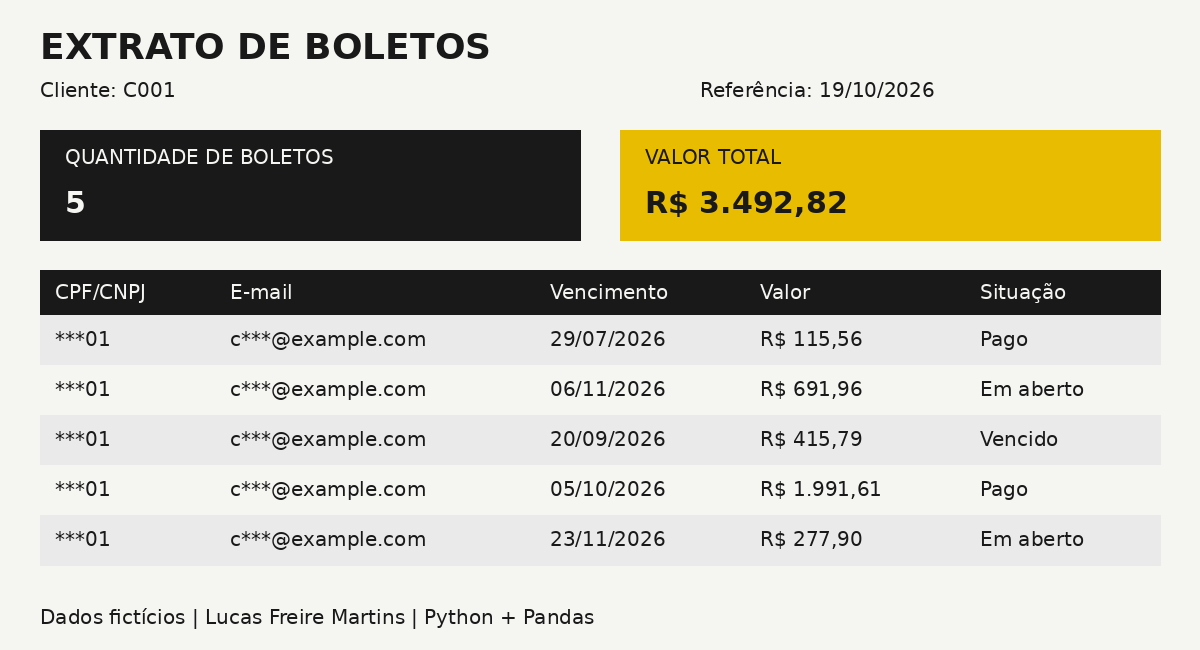

In [7]:
imagem = gerar_imagem(cliente["cliente_id"].iloc[0], extrato, total)
imagem.save("/content/extrato_cliente.png")
display(imagem)

## 8. Gerar um extrato por cliente

In [8]:
from pathlib import Path

pasta = Path("/content/extratos")
pasta.mkdir(exist_ok=True)

for cliente_id, dados in df.groupby("cliente_id"):
    cliente = dados.copy()

    # Mascaramento
    cliente["cpf_cnpj"] = "***" + cliente["cpf_cnpj"].str[-2:]
    cliente["email"] = (
        cliente["email"].str[0] + "***@" +
        cliente["email"].str.split("@").str[1]
    )

    # Resumo
    quantidade = len(cliente)
    total = cliente["valor"].sum()

    # Tabela
    extrato = cliente[
        ["cpf_cnpj", "email", "data_vencimento", "valor", "situacao"]
    ].copy()

    extrato["data_vencimento"] = pd.to_datetime(
        extrato["data_vencimento"]
    ).dt.strftime("%d/%m/%Y")

    extrato["valor"] = extrato["valor"].apply(formatar_real)
    extrato.columns = ["CPF/CNPJ", "E-mail", "Vencimento", "Valor", "Situação"]

    imagem = gerar_imagem(cliente_id, extrato, total)
    imagem.save(pasta / f"extrato_{cliente_id}.png")
    print(f"{cliente_id}: extrato salvo com {quantidade} boletos.")

C001: extrato salvo com 5 boletos.
C002: extrato salvo com 7 boletos.
C003: extrato salvo com 8 boletos.
C004: extrato salvo com 9 boletos.
C005: extrato salvo com 10 boletos.
C006: extrato salvo com 10 boletos.
C007: extrato salvo com 11 boletos.
C008: extrato salvo com 12 boletos.
C009: extrato salvo com 13 boletos.
C010: extrato salvo com 15 boletos.


## 9. Compactar e baixar os extratos

In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/extratos_clientes",
    "zip",
    "/content/extratos"
)

files.download("/content/extratos_clientes.zip")

## Resultado e limites desta versão
- 100 boletos agrupados em 10 extratos individuais.
- Documentos e e-mails parcialmente mascarados nas imagens.
- Quantidade e total de todos os boletos de cada cliente, incluindo pagos.
- Situação fornecida pelo CSV, referente a 19/10/2026.
- Layout dimensionado para esta base e sem paginação.
- O ZIP contém as imagens da pasta `extratos`. Se usar outra base posteriormente, confira se há imagens antigas nessa pasta.
